# 03 · Análisis de rentabilidad y ocupación

**Pregunta de negocio:** ¿dónde y qué tipo de inmueble comprar en Madrid para maximizar la rentabilidad del alquiler turístico?

**Entrada:** tabla `tablon_analitico` (notebook 02). **Salida:** gráficos, insights y mapas en `docs/`.

**Métrica principal:** margen bruto (%) = ingresos anuales ÷ coste de adquisición × 100. Se usa la **mediana** porque hay valores extremos, y se exige un mínimo de registros para que las comparaciones sean fiables.

**Contenido**
1. Configuración y carga de datos
2. Minicubo
3. Rentabilidad (margen bruto)
4. Ocupación
5. Dónde y qué comprar (niveles 1, 2 y 3)
6. Análisis por mapas
7. Conclusiones

## 1. Configuración y carga de datos

In [ ]:
# Importación de librerías
import os
import sqlite3
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from branca.colormap import LinearColormap

In [3]:
# Conexión a la base de datos mercado_inmobiliario y carga de la tabla tablon_analitico en un DataFrame
ruta_db = Path("../datos/intermedios/mercado_inmobiliario.db")

with sqlite3.connect(ruta_db) as conn:
    df = pd.read_sql("SELECT * FROM tablon_analitico", conn)

print(df.shape)

(7295, 27)


## 2. Minicubo

Técnica de BI simplificada: se precalculan las métricas (mediana de cada una) para cada valor de cada dimensión. Permite consultar y graficar cualquier dimensión sin recalcular. Ver `docs/metodologia_minicubos.md`.

In [5]:
# Selección de dimensiones (vistas de análisis) y métricas (lo que se mide)
dimensiones = ['distrito','neighbourhood','room_type','bedrooms_discretizada','accommodates_discretizada','beds_discretizada']
metricas = ['precio_noche_total','estimated_occupancy_l365d','ingresos_anuales','coste_adquisicion','margen_bruto']

In [6]:
# Minicubo: 1) seleccionar variables, 2) pasar las dimensiones a formato transaccional, 3) agregar por 'variable' y 'value'
minicubo = df[dimensiones + metricas]

#Paso 2 - pasar a transaccional las dimensiones
minicubo = minicubo.melt(id_vars=metricas)

#Paso 3 - agregar las métricas por "variable" y "value"
minicubo = minicubo.groupby(['variable','value']).agg(
    conteo = ('precio_noche_total','count'),
    **{f'{m}_mediana': (m,'median') for m in metricas}
).reset_index()
minicubo

,variable,value,conteo,precio_noche_total_mediana,estimated_occupancy_l365d_mediana,ingresos_anuales_mediana,coste_adquisicion_mediana,margen_bruto_mediana
0,accommodates_discretizada,+5_pers,1620,219.5,126.0,26682.0,378836.25,6.360
1,accommodates_discretizada,1_pers,261,60.0,54.0,2728.0,291412.50,0.950
2,accommodates_discretizada,2_pers,2134,113.0,96.0,10515.0,291412.50,4.000
3,accommodates_discretizada,3_pers,808,128.0,120.0,15840.0,291412.50,5.370
4,accommodates_discretizada,4_pers,2472,151.0,114.0,16884.0,291412.50,5.915
...,...,...,...,...,...,...,...,...
156,neighbourhood,Vista Alegre,13,127.0,54.0,10080.0,143587.50,6.020
157,neighbourhood,Zofío,16,87.5,120.0,8401.0,136050.00,5.630
158,room_type,Entire home/apt,6525,150.0,120.0,17472.0,291412.50,5.610
159,room_type,Private room,733,86.0,54.0,4140.0,291412.50,1.760


## 3. Rentabilidad (margen bruto)

### 3.1 Por número de habitaciones

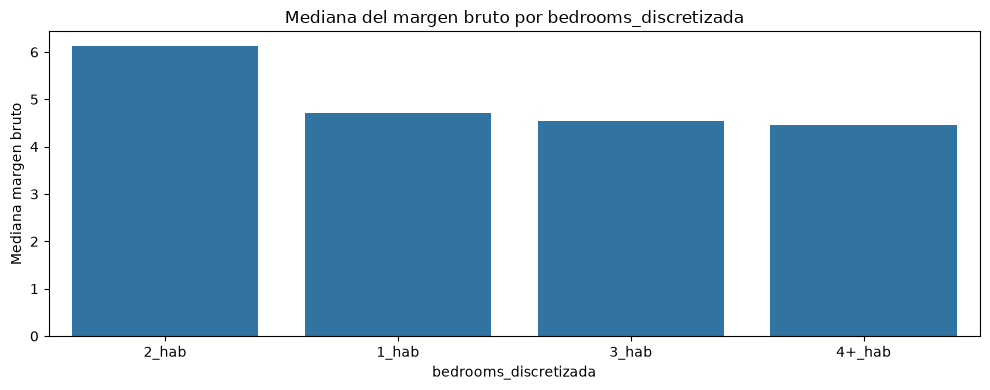

In [7]:
# Mediana del margen bruto por bedrooms_discretizada
data = minicubo[minicubo['variable'] == 'bedrooms_discretizada'].sort_values('margen_bruto_mediana', ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(data=data, x='value', y='margen_bruto_mediana')
plt.title('Mediana del margen bruto por bedrooms_discretizada')
plt.xlabel('bedrooms_discretizada')
plt.ylabel('Mediana margen bruto')
plt.tight_layout()
plt.show()

**Insights**
- Los apartamentos de **2 habitaciones** rinden más (mediana de 6,1%), frente a 4,7% con 1 habitación, 4,6% con 3 y 4,5% con 4 o más.
- A partir de 3 habitaciones la rentabilidad baja: el coste de compra crece más rápido que los ingresos.

### 3.2 Por capacidad (personas)

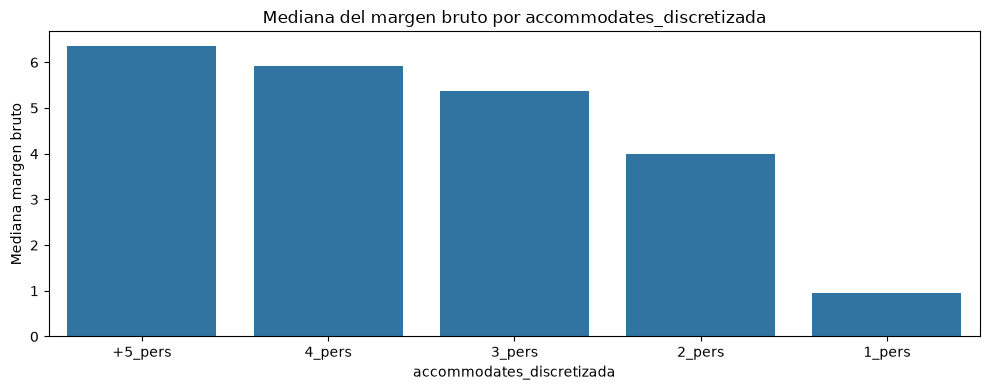

In [8]:
# Mediana del margen bruto por accommodates_discretizada
data = minicubo[minicubo['variable'] == 'accommodates_discretizada'].sort_values('margen_bruto_mediana', ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(data=data, x='value', y='margen_bruto_mediana')
plt.title('Mediana del margen bruto por accommodates_discretizada')
plt.xlabel('accommodates_discretizada')
plt.ylabel('Mediana margen bruto')
plt.tight_layout()
plt.show()

**Insights**
- La rentabilidad **sube con la capacidad**: 5 o más personas 6,4%, 4 personas 5,9%, 3 personas 5,4%, 2 personas 4,0% y 1 persona solo 1,0%.
- Los inmuebles para 4 o más personas son los que mejor aprovechan el precio por noche respecto al coste de compra.

### 3.3 Por tipo de alojamiento

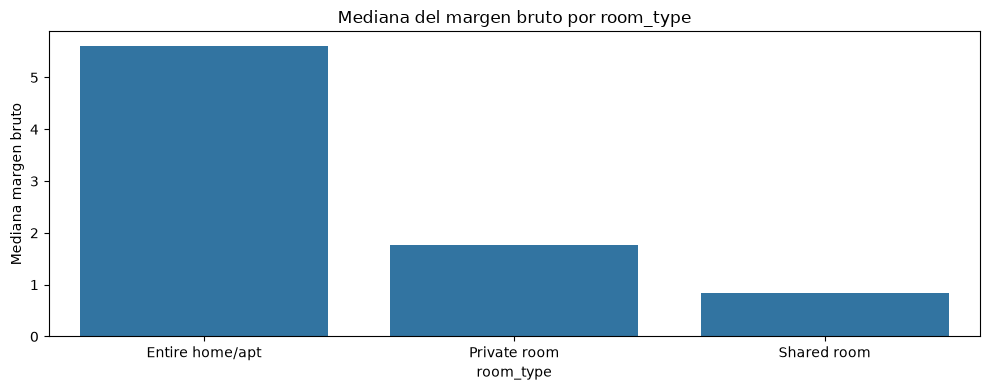

In [9]:
# Mediana del margen bruto por room_type
data = minicubo[minicubo['variable'] == 'room_type'].sort_values('margen_bruto_mediana', ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(data=data, x='value', y='margen_bruto_mediana')
plt.title('Mediana del margen bruto por room_type')
plt.xlabel('room_type')
plt.ylabel('Mediana margen bruto')
plt.tight_layout()
plt.show()

**Insights**
- El **apartamento entero** es el producto rentable: 5,6% de mediana (6.525 anuncios, el 89% de la muestra).
- La habitación privada (1,8%) y la compartida (0,8%) rinden mucho menos: elegir mal el tipo divide la rentabilidad por más de 3.

### 3.4 Por distrito

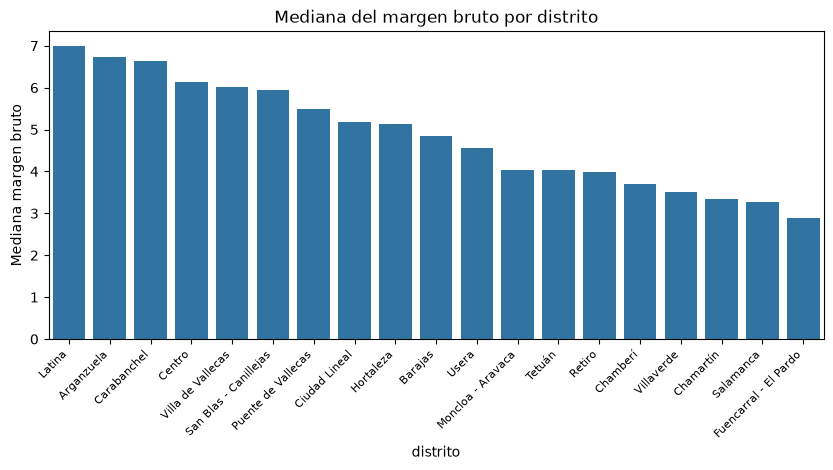

In [10]:
# Mediana del margen bruto por distrito (solo distritos con 30 o más registros)
data = minicubo[(minicubo['variable'] == 'distrito') & (minicubo['conteo'] >= 30)].sort_values('margen_bruto_mediana', ascending=False)
# Se filtraron distritos con menos de 30 registros para evitar distorsiones en la mediana
plt.figure(figsize=(10, 4))
sns.barplot(data=data, x='value', y='margen_bruto_mediana')
plt.title('Mediana del margen bruto por distrito')
plt.xlabel('distrito')
plt.ylabel('Mediana margen bruto')
plt.xticks(rotation=45)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.show()

**Insights**
- **Latina (7,0%), Arganzuela (6,7%), Carabanchel (6,6%) y Centro (6,1%)** superan la mediana de Madrid (5,1%) y tienen muestra suficiente.
- **Salamanca (3,3%), Chamartín (3,3%) y Fuencarral - El Pardo (2,9%)** cierran la tabla.
- Vicálvaro (15 registros) y Moratalaz (16) quedan fuera por tener menos de 30: sus medianas no son fiables.

### 3.5 Dispersión por distrito (boxplot)

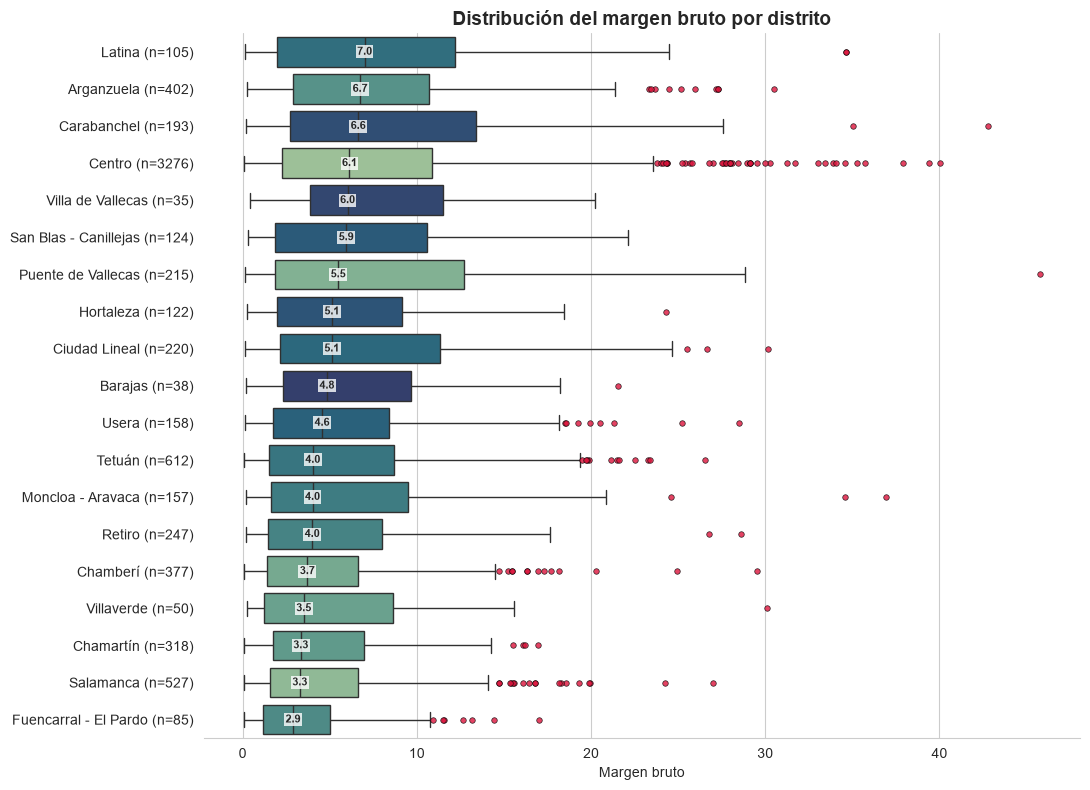

In [18]:
# Boxplots horizontales del margen bruto por distrito, ordenados por mediana
# (se aplican los filtros de registros mínimos y margen máximo)
n_min = 30        # mínimo de registros por distrito
margen_max = 50   # margen bruto máximo a representar

data = df[df['margen_bruto'] <= margen_max]
conteo = data['distrito'].value_counts()
data = data[data['distrito'].isin(conteo[conteo >= n_min].index)]

resumen = data.groupby('distrito')['margen_bruto'].agg(['median','count']).sort_values('median', ascending=False)
orden = resumen.index

with sns.axes_style('whitegrid'):
    plt.figure(figsize=(11, 8))
    ax = sns.boxplot(data=data, x='margen_bruto', y='distrito', order=orden, hue='distrito', palette='crest', legend=False,
                     linewidth=1, flierprops=dict(marker='o', markersize=4, markerfacecolor='crimson', markeredgecolor='black', markeredgewidth=0.5, alpha=0.8))

    # Mediana dentro de cada caja y conteo de registros en la etiqueta
    for i, (distrito, fila) in enumerate(resumen.iterrows()):
        ax.text(fila['median'], i, f"{fila['median']:.1f}", ha='center', va='center', fontsize=8, fontweight='bold',
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=1))
    ax.set_yticks(range(len(orden)))
    ax.set_yticklabels([f"{d} (n={int(n)})" for d, n in resumen['count'].items()])

    ax.set_title('Distribución del margen bruto por distrito', fontsize=14, fontweight='bold')
    ax.set_xlabel('Margen bruto')
    ax.set_ylabel('')
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

**Insights**
- **Mucha dispersión dentro de cada distrito:** en los distritos de interés el 25% inferior queda por debajo de ~3% y el 25% superior supera ~10%. El distrito explica solo una parte del margen; el resto depende del inmueble.
- **Todos los atípicos son valores altos** y no hay márgenes negativos. Los extremos (hasta 81% en Centro) son casos excepcionales que no deben tomarse como referencia.
- **Salamanca, Chamartín y Chamberí** tienen cajas estrechas y medianas bajas: hay poca opción de encontrar una buena compra.
- Para decidir hay que mirar dentro del distrito, filtrando por perfil de inmueble.

### 3.6 Perfil foco

(1821, 27)


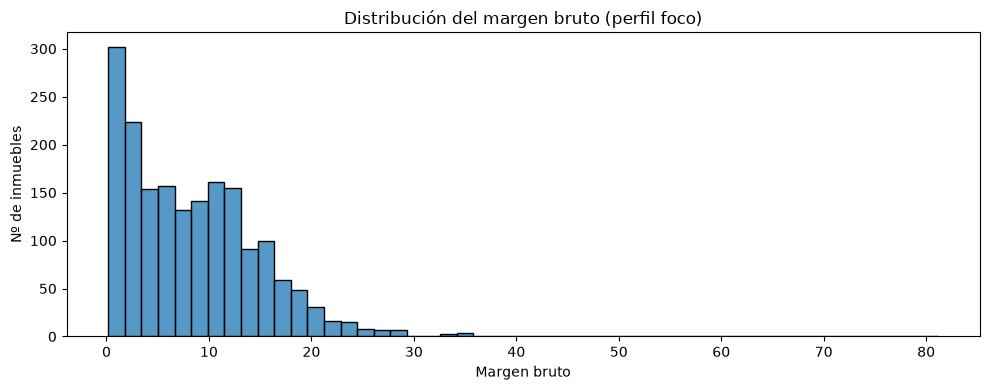

In [11]:
# Perfil foco: apartamento entero de 1 o 2 habitaciones, 4 o más personas, en Vicálvaro, Latina, Arganzuela, Carabanchel y Centro.
# Se filtra el df en df_foco y se grafica el histograma del margen bruto para ver su distribución y los outliers.
df_foco = df[
    df['bedrooms_discretizada'].isin(['1_hab','2_hab'])
    & df['accommodates_discretizada'].isin(['4_pers','+5_pers'])
    & df['distrito'].isin(['Vicálvaro','Latina','Arganzuela','Carabanchel','Centro'])
    & df['room_type'].isin(['Entire home/apt'])
].copy()

print(df_foco.shape)

plt.figure(figsize=(10, 4))
sns.histplot(data=df_foco, x='margen_bruto', bins=50)
plt.title('Distribución del margen bruto (perfil foco)')
plt.xlabel('Margen bruto')
plt.ylabel('Nº de inmuebles')
plt.tight_layout();

**Insights**
- El perfil foco reúne **1.821 inmuebles** (Centro 1.466, Arganzuela 199, Carabanchel 102, Latina 44 y Vicálvaro 10) con un margen mediano de **7,5%**.
- La distribución es **asimétrica a la derecha**: el 50% central va de 2,8% a 12,3%, el 95% está por debajo de 19,8% y el máximo llega a 81%.
- El **39% supera el 10%** y solo 86 inmuebles superan el 20%: son excepciones, no la expectativa.

## 4. Ocupación

### 4.1 Por capacidad (personas)

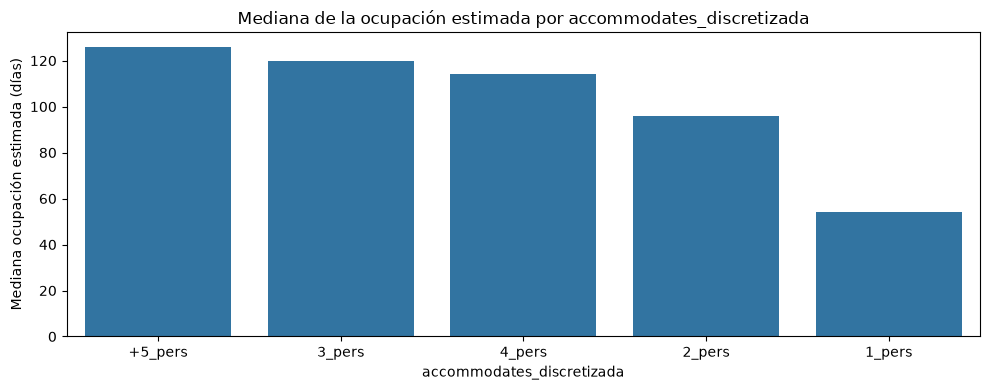

In [13]:
# Mediana de la ocupación estimada por accommodates_discretizada
data = minicubo[minicubo['variable'] == 'accommodates_discretizada'].sort_values('estimated_occupancy_l365d_mediana', ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(data=data, x='value', y='estimated_occupancy_l365d_mediana')
plt.title('Mediana de la ocupación estimada por accommodates_discretizada')
plt.xlabel('accommodates_discretizada')
plt.ylabel('Mediana ocupación estimada (días)')
plt.tight_layout()
plt.show()

**Insights**
- La ocupación **crece con la capacidad**: 1 persona 54 días, 2 personas 96, 4 personas 114, 3 personas 120 y 5 o más 126.
- Los inmuebles de 5 o más personas son los más ocupados del año.

### 4.2 Por número de habitaciones

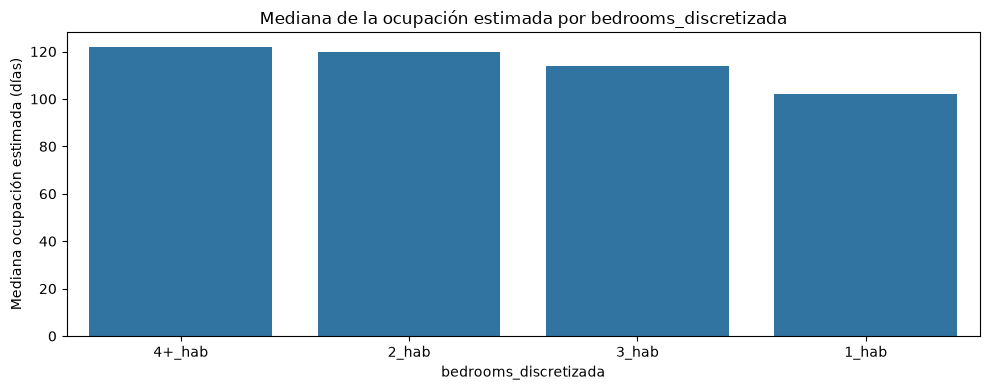

In [14]:
# Mediana de la ocupación estimada por bedrooms_discretizada
data = minicubo[minicubo['variable'] == 'bedrooms_discretizada'].sort_values('estimated_occupancy_l365d_mediana', ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(data=data, x='value', y='estimated_occupancy_l365d_mediana')
plt.title('Mediana de la ocupación estimada por bedrooms_discretizada')
plt.xlabel('bedrooms_discretizada')
plt.ylabel('Mediana ocupación estimada (días)')
plt.tight_layout()
plt.show()

**Insights**
- Los de **4 o más habitaciones (122 días) y 2 habitaciones (120)** tienen la mayor ocupación; 3 habitaciones 114 y 1 habitación 102.
- La ocupación de 2 habitaciones se suma a su mayor margen: es el tamaño más equilibrado.

### 4.3 Por tipo de alojamiento

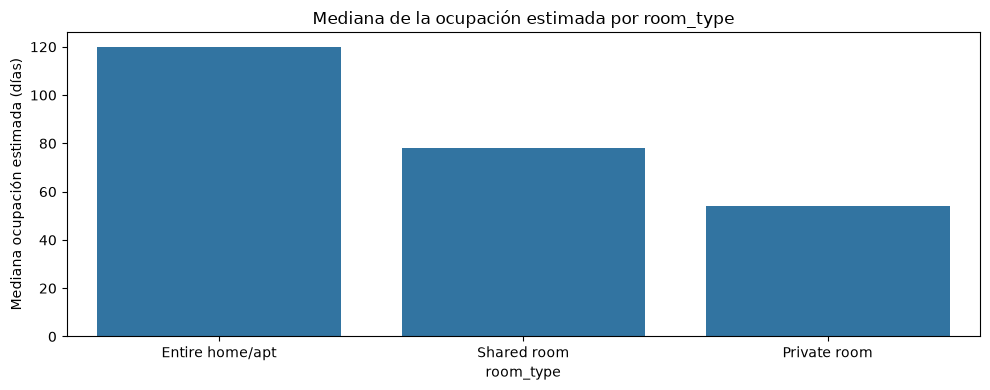

In [15]:
# Mediana de la ocupación estimada por room_type
data = minicubo[minicubo['variable'] == 'room_type'].sort_values('estimated_occupancy_l365d_mediana', ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(data=data, x='value', y='estimated_occupancy_l365d_mediana')
plt.title('Mediana de la ocupación estimada por room_type')
plt.xlabel('room_type')
plt.ylabel('Mediana ocupación estimada (días)')
plt.tight_layout()
plt.show()

**Insights**
- El apartamento entero (120 días) más que duplica la ocupación de la habitación privada (54 días).
- La habitación compartida (78 días) solo tiene 37 anuncios: no es concluyente.

### 4.4 Ocupación frente a margen bruto

(7292, 27)


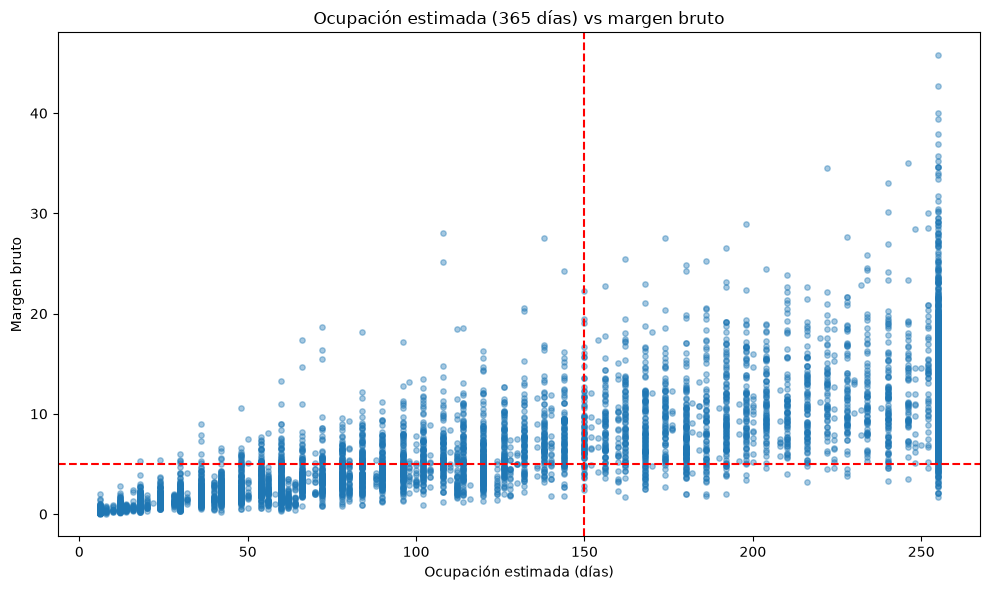

In [12]:
# Scatter: ocupación estimada (365 días) vs margen bruto (margen ≤ 50%), con líneas de referencia en 150 días y 5%
data = df[df['margen_bruto'] <= 50]
print(data.shape)
plt.figure(figsize=(10, 6))
plt.scatter(data['estimated_occupancy_l365d'], data['margen_bruto'], alpha=0.4, s=15)
plt.axvline(x=150, color='red', linestyle='--')
plt.axhline(y=5, color='red', linestyle='--')
plt.title('Ocupación estimada (365 días) vs margen bruto')
plt.xlabel('Ocupación estimada (días)')
plt.ylabel('Margen bruto')
plt.tight_layout()
plt.show()

**Insights**
- Existe una **relación positiva**: más días de ocupación implican más ingresos y, por tanto, más margen.
- El **37% de los inmuebles** (2.684 de 7.292) supera a la vez 150 días de ocupación y 5% de margen.
- Hay inmuebles con alta ocupación y margen bajo (coste de compra alto) y al revés: hay que mirar ambas métricas juntas.

### 4.5 Ocupación por distrito y tipo de alojamiento

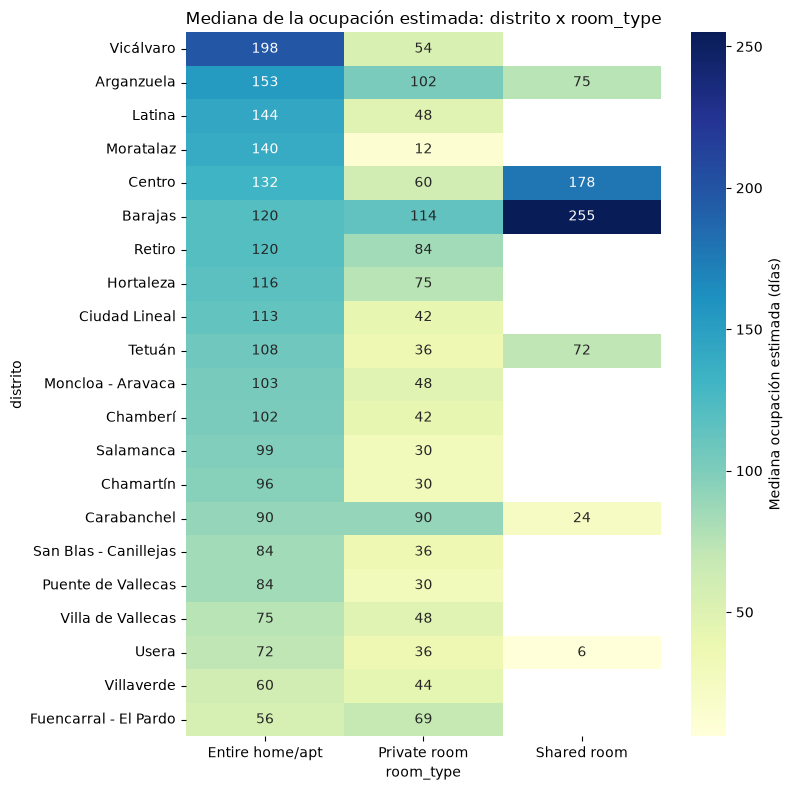

In [16]:
# Heatmap: mediana de la ocupación estimada por distrito x room_type
tabla = df.pivot_table(index='distrito', columns='room_type', values='estimated_occupancy_l365d', aggfunc=['median','count'])
mediana = tabla['median'].where(tabla['count'] >= 0)
mediana = mediana.dropna(how='all').dropna(axis=1, how='all')
mediana = mediana.sort_values(by=mediana.columns[0], ascending=False)

plt.figure(figsize=(8, 8))
sns.heatmap(mediana, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Mediana ocupación estimada (días)'})
plt.title('Mediana de la ocupación estimada: distrito x room_type')
plt.xlabel('room_type')
plt.ylabel('distrito')
plt.tight_layout()
plt.show()

**Insights**
- En el apartamento entero destacan **Arganzuela (153 días), Latina (144) y Centro (132)**.
- Vicálvaro (198) y Moratalaz (140) aparecen arriba, pero con muy pocos anuncios (Vicálvaro 12 en apartamento entero; Moratalaz 16 en total): no son fiables.
- La habitación privada tiene entre 48 y 102 días en Latina, Arganzuela y Centro; las casillas de habitación compartida tienen muy pocos registros.

### 4.6 Caso Barajas

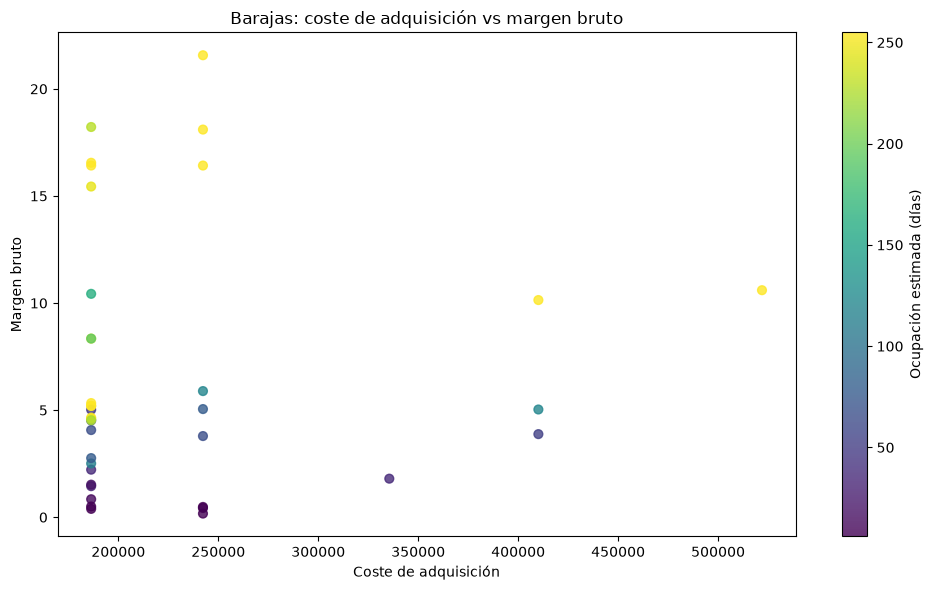

In [17]:
# Scatter de Barajas: coste de adquisición vs margen bruto, con el color según la ocupación estimada
data = df[df['distrito'] == 'Barajas']

plt.figure(figsize=(10, 6))
sc = plt.scatter(data['coste_adquisicion'], data['margen_bruto'], c=data['estimated_occupancy_l365d'], cmap='viridis', alpha=0.8, s=40)
plt.colorbar(sc, label='Ocupación estimada (días)')
plt.title('Barajas: coste de adquisición vs margen bruto')
plt.xlabel('Coste de adquisición')
plt.ylabel('Margen bruto')
plt.tight_layout()
plt.show()

**Insights**
- Barajas tiene solo **38 anuncios** (mediana de margen 4,8% y 120 días de ocupación).
- El margen depende casi por completo de la **ocupación** (correlación de Spearman 0,87) y no del coste de compra (0,05): los inmuebles más ocupados son los más rentables.
- La muestra es pequeña, por lo que es un caso para explorar, no para generalizar.

## 5. Dónde y qué comprar

### 5.1 Nivel 1 · Latina, Arganzuela, Carabanchel y Centro

In [19]:
# Se filtra el df con los distritos de interés
interes = ['Latina','Arganzuela','Carabanchel','Centro']
df_seleccion = df[df['distrito'].isin(interes)]

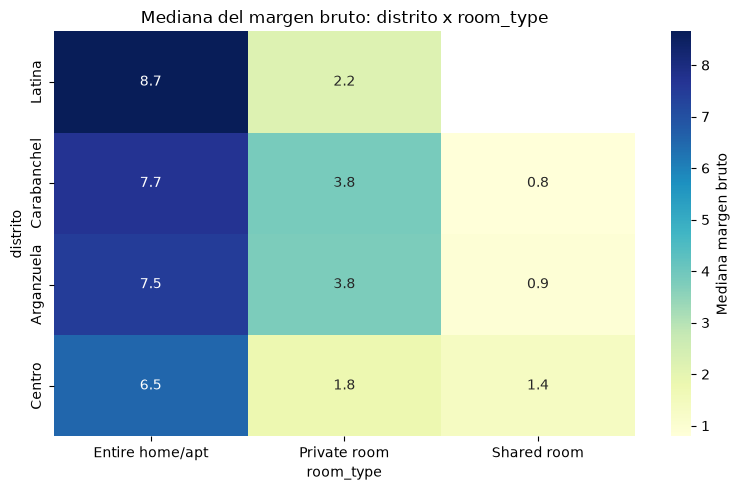

In [20]:
# Heatmap de distrito x room_type con la mediana del margen bruto
n_min = 0  # mínimo de registros por cruce

tabla = df_seleccion.pivot_table(index='distrito', columns='room_type', values='margen_bruto', aggfunc=['median','count'])
mediana = tabla['median'].where(tabla['count'] >= n_min).dropna(how='all').dropna(axis=1, how='all')
mediana = mediana.sort_values(by=mediana.columns[0], ascending=False)

plt.figure(figsize=(8, 5))
sns.heatmap(mediana, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': 'Mediana margen bruto'})
plt.title('Mediana del margen bruto: distrito x room_type')
plt.xlabel('room_type')
plt.ylabel('distrito')
plt.tight_layout()
plt.show()

**Insights**
- El **apartamento entero** rinde entre 6,5% y 8,7%: **Latina 8,7%** (78 inmuebles), Carabanchel 7,7%, Arganzuela 7,5% y Centro 6,5%.
- La habitación privada no supera el 3,8% en ningún distrito y la compartida casi no existe (1 a 6 inmuebles).

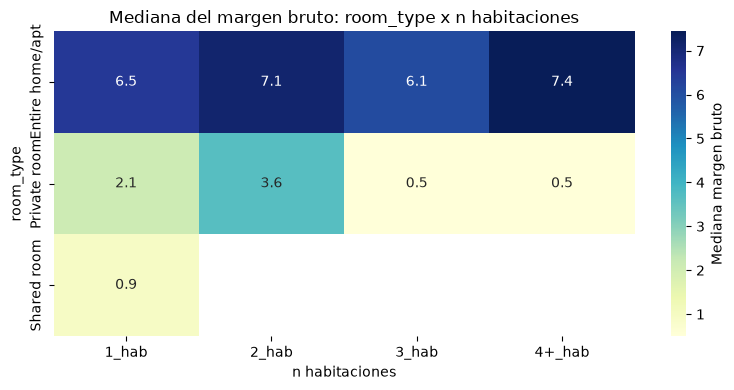

In [22]:
# Heatmap de room_type x número de habitaciones con la mediana del margen bruto
n_min = 0  # mínimo de registros por cruce

tabla = df_seleccion.pivot_table(index='room_type', columns='bedrooms_discretizada', values='margen_bruto', aggfunc=['median','count'])
mediana = tabla['median'].where(tabla['count'] >= n_min).dropna(how='all').dropna(axis=1, how='all')

plt.figure(figsize=(8, 4))
sns.heatmap(mediana, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': 'Mediana margen bruto'})
plt.title('Mediana del margen bruto: room_type x n habitaciones')
plt.xlabel('n habitaciones')
plt.ylabel('room_type')
plt.tight_layout()
plt.show()

**Insights**
- En apartamento entero, **2 habitaciones (7,1%, 1.133 inmuebles)** supera a 1 habitación (6,5%, 2.121) y a 3 habitaciones (6,1%).
- Las celdas de 4 o más habitaciones y las de habitación privada tienen pocos inmuebles: no usar.

### 5.2 Nivel 2 · Resto de distritos

In [24]:
# Se filtra el df por room_type = Entire home/apt, excluyendo los distritos de interés
df_resto = df[(df['room_type'] == 'Entire home/apt') & (~df['distrito'].isin(interes))].copy()

print(df_resto.shape)

(2882, 27)


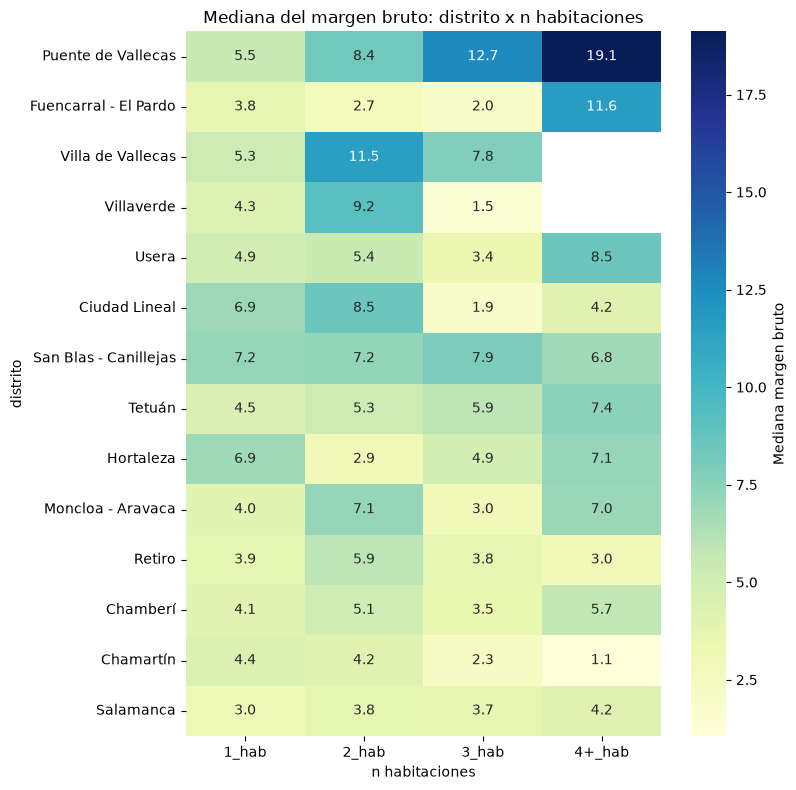

In [28]:
# Heatmap de distrito x número de habitaciones con la mediana del margen bruto (solo distritos con 30 o más registros)
n_min = 30  # mínimo de registros por distrito

conteo = df_resto['distrito'].value_counts()
data = df_resto[df_resto['distrito'].isin(conteo[conteo >= n_min].index)]

mediana = data.pivot_table(index='distrito', columns='bedrooms_discretizada', values='margen_bruto', aggfunc='median')
mediana = mediana.loc[mediana.max(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(8, 8))
sns.heatmap(mediana, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': 'Mediana margen bruto'})
plt.title('Mediana del margen bruto: distrito x n habitaciones')
plt.xlabel('n habitaciones')
plt.ylabel('distrito')
plt.tight_layout()
plt.show()

**Insights: qué comprar según el n.º de habitaciones (resto de distritos, Entire home/apt)**

*Solo se consideran fiables las casillas con muestra suficiente (más de ~30 inmuebles, 20 como mínimo).*

**Visión general**
- El tipo que mejor funciona es el de **2 habitaciones**: mediana de margen de 5,1, frente a 4,6 (1 hab), 3,7 (3 hab) y 4,2 (4+ hab).
- Los de 3 o más habitaciones rinden menos porque el coste de adquisición sube más rápido que los ingresos (mediana de ~670.000 € frente a ~396.000 € en 2 habitaciones).
- Los de 1 habitación son los más abundantes y baratos (~231.000 €), pero con menos ingresos.

**Recomendación por distrito**
- **Puente de Vallecas:** 2 habitaciones (8,4). El de 1 habitación queda en 5,4.
- **Ciudad Lineal:** 1 o 2 habitaciones (6,9 y 8,5).
- **Tetuán:** 3 habitaciones (5,9), con mejora progresiva según sube el tamaño.
- **Retiro, Chamberí, Moncloa - Aravaca y Usera:** 2 habitaciones.
- **San Blas - Canillejas:** 1 o 2 habitaciones (7,2 en ambas).
- **Chamartín:** 1 habitación (4,4); evitar 3 o más (2,3).
- **Salamanca:** evitar, con medianas de 3,0 a 4,2 en todos los tamaños.

**Hallazgos que no conviene usar**
- Las casillas de 4+ habitaciones tienen entre 1 y 13 inmuebles; el 19,1 de Puente de Vallecas y el 11,6 de Fuencarral son anécdotas.
- Villa de Vallecas (2 hab, 11,5) y Villaverde (2 hab, 9,2) salen de 8 y 4 inmuebles.
- Las medianas de Hortaleza y Fuencarral - El Pardo saltan sin patrón claro.

**Conclusión práctica**
- Ciudad Lineal y Puente de Vallecas son los candidatos más interesantes fuera de los cuatro distritos de interés.
- Antes de decidir hay que cruzar con el coste de adquisición y la ocupación de cada casilla, porque este heatmap solo mide el margen.

### 5.3 Nivel 3 · Perfiles de inmuebles a nivel barrio

In [31]:
# Tabla de perfiles (distrito, barrio, habitaciones, capacidad): mediana de margen bruto y ocupación, con un mínimo de registros por perfil
n_min = 10  # mínimo de registros por perfil

perfiles = (df_resto
    .groupby(['distrito','neighbourhood','bedrooms_discretizada','accommodates_discretizada'])
    .agg(conteo=('margen_bruto','count'),
         margen_bruto_mediana=('margen_bruto','median'),
         estimated_occupancy_mediana=('estimated_occupancy_l365d','median'))
    .reset_index())

perfiles = (perfiles[perfiles['conteo'] >= n_min]
    .sort_values('margen_bruto_mediana', ascending=False)
    .reset_index(drop=True))
perfiles

,distrito,neighbourhood,bedrooms_discretizada,accommodates_discretizada,conteo,margen_bruto_mediana,estimated_occupancy_mediana
0,Puente de Vallecas,Numancia,1_hab,4_pers,15,13.040,132.0
1,Puente de Vallecas,San Diego,2_hab,4_pers,12,10.515,195.0
2,Usera,Almendrales,1_hab,4_pers,11,10.230,160.0
3,San Blas - Canillejas,Canillejas,1_hab,2_pers,10,9.885,192.0
4,Ciudad Lineal,Ventas,1_hab,4_pers,23,9.770,156.0
...,...,...,...,...,...,...,...
82,Salamanca,Guindalera,2_hab,4_pers,20,1.740,60.0
83,Tetuán,Bellas Vistas,1_hab,2_pers,14,1.700,34.0
84,Tetuán,Bellas Vistas,1_hab,4_pers,14,1.650,24.0
85,Tetuán,Valdeacederas,1_hab,2_pers,23,1.480,60.0


**Insights**
- Los perfiles con mayor margen fuera de los cuatro distritos son apartamentos de **1 o 2 habitaciones en Puente de Vallecas (Numancia 13,0%, San Diego 10,5%), Usera (Almendrales 10,2%), San Blas (Canillejas 9,9%), Ciudad Lineal (Ventas 9,8%) y Tetuán**.
- Combinan margen alto con **132–200 días de ocupación**, pero con solo 10 a 29 inmuebles por perfil: son una lista de búsqueda, no un veredicto.

## 6. Análisis por mapas

Los mapas se guardan como HTML en la carpeta `docs/`.

In [34]:
# Mapa de calor de la rentabilidad (margen bruto) con la función de funciones.py (margen recortado a 50%)
import sys
sys.path.append(str(Path("../funciones").resolve()))

from funciones import crear_mapa_calor_score

margen_max = 100  # se recortan los outliers para que no dominen el mapa
df_mapa = df.copy()
df_mapa['margen_bruto_100'] = df_mapa['margen_bruto'].clip(upper=margen_max) / margen_max * 100  # escala 0-100 que espera la función

mapa = crear_mapa_calor_score(df_mapa, ruta_salida='../docs/mapa_calor_margen_bruto.html', col_score='margen_bruto_100')
mapa

Mapa guardado en: G:\Mi unidad\AREAS DE VIDA\2. CRECIMIENTO\ESTUDIO\DATA SCIENCE\DATA SCIENCE MASTERY IA EDITION\0. PROYECTOS\1. ANALISIS AIRBNB ALQUILER TURISTICO\docs\mapa_calor_margen_bruto.html


In [35]:
# Mapa de calor de la ocupación estimada con la misma función
df_mapa_ocup = df.copy()
df_mapa_ocup['ocupacion_100'] = df_mapa_ocup['estimated_occupancy_l365d'] / 365 * 100  # escala 0-100 que espera la función

mapa_ocup = crear_mapa_calor_score(df_mapa_ocup, ruta_salida='../docs/mapa_calor_ocupacion.html', col_score='ocupacion_100')
mapa_ocup

Mapa guardado en: G:\Mi unidad\AREAS DE VIDA\2. CRECIMIENTO\ESTUDIO\DATA SCIENCE\DATA SCIENCE MASTERY IA EDITION\0. PROYECTOS\1. ANALISIS AIRBNB ALQUILER TURISTICO\docs\mapa_calor_ocupacion.html


**Insights**
- La intensidad del mapa refleja **densidad × valor**: Centro concentra el 45% de los anuncios y por eso domina la imagen.
- Sirven para localizar zonas y barrios, no para comparar distritos entre sí: para eso están las medianas de las secciones 3 a 5.

In [37]:
# Mapa de puntos de oportunidad: margen bruto > 20% y ocupación estimada > 200 días
# (tamaño y color según el margen bruto; tooltip con las métricas del inmueble)
margen_min = 20
ocupacion_min = 200

oportunidades = df[(df['margen_bruto'] > margen_min) & (df['estimated_occupancy_l365d'] > ocupacion_min)].dropna(subset=['latitude','longitude'])
print(oportunidades.shape)

# Color en gradiente y tamaño de la burbuja según el margen bruto
m_min, m_max = oportunidades['margen_bruto'].min(), oportunidades['margen_bruto'].max()
colores = LinearColormap(['gold', 'orange', 'red', 'darkred'], vmin=m_min, vmax=m_max, caption='Margen bruto')

def radio(margen):
    return 5 + (margen - m_min) / (m_max - m_min) * 20  # entre 5 y 25 px

mapa_oport = folium.Map(location=[40.4168, -3.7038], zoom_start=12, tiles='OpenStreetMap')

for _, fila in oportunidades.iterrows():
    info = (f"<b>{fila['distrito']} - {fila['neighbourhood']}</b><br>"
            f"{fila['room_type']} | {fila['bedrooms_discretizada']} | {fila['accommodates_discretizada']}<br>"
            f"Margen bruto: {fila['margen_bruto']:.1f}<br>"
            f"Ocupación: {fila['estimated_occupancy_l365d']:.0f} días<br>"
            f"Precio noche: {fila['precio_noche_total']:,.0f} €<br>"
            f"Ingresos anuales: {fila['ingresos_anuales']:,.0f} €<br>"
            f"Coste adquisición: {fila['coste_adquisicion']:,.0f} €")
    folium.CircleMarker(
        location=[fila['latitude'], fila['longitude']],
        radius=radio(fila['margen_bruto']),
        color='black',
        weight=1,
        fill=True,
        fill_color=colores(fila['margen_bruto']),
        fill_opacity=0.75,
        tooltip=folium.Tooltip(info, sticky=True),
    ).add_to(mapa_oport)

colores.add_to(mapa_oport)
mapa_oport.save('../docs/mapa_oportunidades.html')
mapa_oport

(152, 27)


**Insights**
- **152 inmuebles** combinan margen superior al 20% y ocupación superior a 200 días: 74 en Centro, 15 en Puente de Vallecas, 14 en Arganzuela y 11 en Carabanchel.
- 150 de los 152 son apartamentos enteros, el 76% admite 4 o más personas y el 94% tiene 1 o 2 habitaciones.
- Su margen mediano es 23,6% con un coste mediano de 291.413 €. Son casos excepcionales (2% del total): útiles como lista de visitas.

## 7. Conclusiones: ¿dónde debemos comprar inmuebles?

**Respuesta:** apartamentos **enteros de 2 habitaciones y capacidad para 4 o más personas** en **Latina, Carabanchel, Arganzuela y Centro**, con **Puente de Vallecas y Ciudad Lineal** como segunda línea.

| Prioridad | Dónde | Qué | Evidencia |
|---|---|---|---|
| 1 | Latina, Carabanchel, Arganzuela, Centro | Apartamento entero, 2 hab., 4+ personas | Margen mediano de 6,1% a 7,0% por distrito y 7,1% a 8,0% con 2 habitaciones |
| 2 | Puente de Vallecas, Ciudad Lineal | 2 habitaciones | 8,4% y 8,5% |
| Descartar | Salamanca, Chamartín, Fuencarral - El Pardo | Habitación privada o compartida, capacidad de 1 persona | Márgenes de 0,8% a 3,3% |

**Para decidir:** las medianas dan una referencia, pero cada inmueble varía mucho. Antes de invertir hay que validar la ocupación con reservas reales y añadir costes operativos, reforma y financiación (el margen bruto no los incluye).